# Notebook 01: Dataset Exploration & Schema Inspection
## Analysis of Air Pollution Patterns and Hotspots Across India Using Apache Spark

**Source:** XKDR Forum India Air Quality Database (`https://airquality.xkdr.org`)

### Objectives:
1. Inspect the official XKDR air quality schema and data dictionary.
2. Initialize an optimized local Apache Spark session.
3. Ingest real historical hourly observations (January 2024 sample of 4+ million records).
4. Explore pollutant parameters, measurement units, and monitoring stations.
5. Execute initial Spark SQL aggregations and produce exploratory visualizations.

In [1]:
import sys
import os
from pathlib import Path

# Ensure project root is in sys.path
PROJECT_ROOT = Path(os.getcwd()).resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import src.config as config
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, avg, min, max, stddev, round

print('Dependencies loaded successfully!')
print('Project Root:', PROJECT_ROOT)

Dependencies loaded successfully!
Project Root: C:\Users\deore\Desktop\bda project


In [2]:
# Initialize SparkSession with optimized local settings
spark = (
    SparkSession.builder
    .appName('BDA_01_Dataset_Exploration')
    .master('local[*]')
    .config('spark.sql.shuffle.partitions', '4')
    .config('spark.driver.memory', '4g')
    .config('spark.ui.enabled', 'false')
    .getOrCreate()
)

print(f'SparkSession Active | Spark Version: {spark.version} | Master: {spark.sparkContext.master}')

SparkSession Active | Spark Version: 3.5.3 | Master: local[*]


### Ingesting Real Historical Measurements & Metadata
We load the downloaded sample month (`measurements_2024_01.parquet`), monitoring stations (`stations.parquet`), and parameter definitions (`parameters.parquet`).

In [3]:
sample_parquet_path = PROJECT_ROOT / 'data' / 'sample' / 'measurements_2024_01.parquet'
stations_parquet_path = PROJECT_ROOT / 'data' / 'metadata' / 'stations.parquet'
parameters_parquet_path = PROJECT_ROOT / 'data' / 'metadata' / 'parameters.parquet'

df_measurements = spark.read.parquet(str(sample_parquet_path))
df_stations = spark.read.parquet(str(stations_parquet_path))
df_parameters = spark.read.parquet(str(parameters_parquet_path))

total_records = df_measurements.count()
print(f'Total Real Observations in Sample Month: {total_records:,}')
print(f'Total Monitoring Stations in India: {df_stations.count():,}')
print(f'Total Tracked Pollutants & Meteorological Parameters: {df_parameters.count():,}')

Total Real Observations in Sample Month: 4,002,852


Total Monitoring Stations in India: 558


Total Tracked Pollutants & Meteorological Parameters: 15


### Measurements Schema Inspection

In [4]:
print('--- Measurements Schema ---')
df_measurements.printSchema()

print('--- First 5 Real Observations ---')
df_measurements.show(5, truncate=False)

--- Measurements Schema ---
root
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- state_name: string (nullable = true)
 |-- city_name: string (nullable = true)
 |-- parameter_name: string (nullable = true)
 |-- unit: string (nullable = true)
 |-- collected_at: timestamp_ntz (nullable = true)
 |-- value: double (nullable = true)
 |-- source: string (nullable = true)

--- First 5 Real Observations ---


+----------+----------------------+----------+---------+--------------+-----+-------------------+-----+----------+
|station_id|station_name          |state_name|city_name|parameter_name|unit |collected_at       |value|source    |
+----------+----------------------+----------+---------+--------------+-----+-------------------+-----+----------+
|DS1010001 |US Embassy - New Delhi|Delhi     |New Delhi|PM2.5         |µg/m³|2024-01-01 00:30:00|197.0|us_embassy|
|DS1010001 |US Embassy - New Delhi|Delhi     |New Delhi|PM2.5         |µg/m³|2024-01-01 01:30:00|194.0|us_embassy|
|DS1010001 |US Embassy - New Delhi|Delhi     |New Delhi|PM2.5         |µg/m³|2024-01-01 02:30:00|179.0|us_embassy|
|DS1010001 |US Embassy - New Delhi|Delhi     |New Delhi|PM2.5         |µg/m³|2024-01-01 03:30:00|180.0|us_embassy|
|DS1010001 |US Embassy - New Delhi|Delhi     |New Delhi|PM2.5         |µg/m³|2024-01-01 04:30:00|182.0|us_embassy|
+----------+----------------------+----------+---------+--------------+-----+---

### Observations Distribution Across Pollutants & Units

In [5]:
pollutant_dist = (
    df_measurements.groupBy('parameter_name', 'unit')
    .agg(count('*').alias('observation_count'),
         round(avg('value'), 2).alias('mean_val'),
         round(min('value'), 2).alias('min_val'),
         round(max('value'), 2).alias('max_val'))
    .orderBy(col('observation_count').desc())
)
pollutant_dist.show(15, truncate=False)

+--------------+-----+-----------------+--------+-------+-------+
|parameter_name|unit |observation_count|mean_val|min_val|max_val|
+--------------+-----+-----------------+--------+-------+-------+
|NOx           |ppb  |343938           |29.59   |0.0    |499.5  |
|NO2           |µg/m³|342047           |27.5    |0.01   |491.9  |
|PM2.5         |µg/m³|339111           |85.37   |0.01   |1000.0 |
|NO            |µg/m³|337320           |14.51   |0.01   |499.64 |
|CO            |mg/m³|336807           |1.06    |0.0    |12.68  |
|PM10          |µg/m³|331820           |155.46  |0.19   |999.99 |
|SO2           |µg/m³|331052           |13.38   |0.01   |199.83 |
|Ozone         |µg/m³|330538           |27.55   |0.01   |199.7  |
|NH3           |µg/m³|306407           |25.21   |0.01   |479.18 |
|Benzene       |µg/m³|293974           |2.97    |0.0    |213.17 |
|Toluene       |µg/m³|225552           |9.82    |0.0    |496.1  |
|MP-Xylene     |µg/m³|208731           |4.37    |0.01   |499.1  |
|Eth-Benze

### City-Level PM2.5 Analysis (January 2024 Sample)

In [6]:
# Register as Spark SQL temporary view
df_measurements.createOrReplaceTempView('measurements')

query = '''
SELECT 
    city_name,
    state_name,
    COUNT(value) as valid_readings,
    ROUND(AVG(value), 2) as avg_pm25,
    ROUND(MIN(value), 2) as min_pm25,
    ROUND(MAX(value), 2) as max_pm25
FROM measurements
WHERE parameter_name = 'PM2.5' AND value >= 0
GROUP BY city_name, state_name
HAVING COUNT(value) >= 500
ORDER BY avg_pm25 DESC
LIMIT 10
'''
top_cities_pm25 = spark.sql(query)
top_cities_pm25.show(10, truncate=False)

+--------------+----------------+--------------+--------+--------+--------+
|city_name     |state_name      |valid_readings|avg_pm25|min_pm25|max_pm25|
+--------------+----------------+--------------+--------+--------+--------+
|New Delhi     |Delhi           |743           |242.78  |26.0    |687.0   |
|Delhi         |Delhi           |27244         |205.98  |5.3     |1000.0  |
|Bhagalpur     |Bihar           |1370          |204.66  |67.5    |649.5   |
|Saharsa       |Bihar           |676           |187.21  |50.5    |526.0   |
|Byrnihat      |Assam           |594           |175.63  |17.0    |669.25  |
|Greater Noida |Uttar Pradesh   |1302          |170.32  |47.0    |528.0   |
|Noida         |Uttar Pradesh   |2823          |168.75  |31.0    |993.0   |
|Hanumangarh   |Rajasthan       |741           |165.27  |42.75   |607.0   |
|Baddi         |Himachal Pradesh|703           |162.44  |19.25   |639.75  |
|Sri Ganganagar|Rajasthan       |727           |159.36  |47.75   |557.5   |
+-----------

### Exploratory Visualizations: Top 10 PM2.5 Cities in January 2024

C:\Users\deore\AppData\Local\Temp\ipykernel_14584\3792548161.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


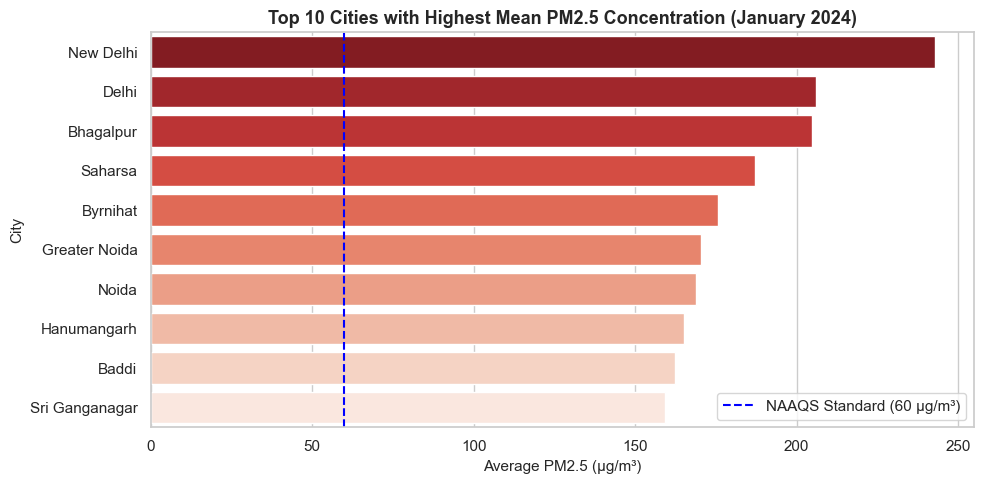

Chart saved to C:\Users\deore\Desktop\bda project\outputs\charts\01_top_pm25_cities_jan2024.png


In [7]:
top_cities_pd = top_cities_pm25.toPandas()

plt.figure(figsize=(10, 5), dpi=100)
sns.set_theme(style='whitegrid')
ax = sns.barplot(
    data=top_cities_pd,
    x='avg_pm25',
    y='city_name',
    palette='Reds_r'
)
# Add NAAQS 24-hr threshold line (60 ug/m3)
plt.axvline(60, color='blue', linestyle='--', linewidth=1.5, label='NAAQS Standard (60 µg/m³)')
plt.title('Top 10 Cities with Highest Mean PM2.5 Concentration (January 2024)', fontsize=13, weight='bold')
plt.xlabel('Average PM2.5 (µg/m³)', fontsize=11)
plt.ylabel('City', fontsize=11)
plt.legend(loc='lower right')
plt.tight_layout()

# Save chart to outputs directory
chart_path = PROJECT_ROOT / 'outputs' / 'charts' / '01_top_pm25_cities_jan2024.png'
plt.savefig(chart_path)
plt.show()
print(f'Chart saved to {chart_path}')

### Conclusion & Spark Cleanup

In [8]:
spark.stop()
print('SparkSession stopped cleanly.')

SparkSession stopped cleanly.
